In [4]:
import os
from google.colab import drive

drive.mount('/content/drive')

REPO_URL = "https://github.com/doanhailong8197-ai/spatial-gmm-vae.git"
REPO_NAME = "spatial-gmm-vae"

if not os.path.exists(f"/content/{REPO_NAME}"):
    !git clone {REPO_URL}

%cd /content/{REPO_NAME}/Methods

!pip install -q scanpy anndata scikit-learn

import math
import random
import warnings
import numpy as np
import pandas as pd
import scanpy as sc
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import DataLoader
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.neighbors import NearestNeighbors

from preprocess import preprocess_pipeline
from model import (Encoder, Decoder, DomainClassifier, GMM_VAE,
                   pretrain_vae, initialize_gmm_parameters, train_joint_gmm_vae,
                   extract_mu, build_spatial_neighbors, compute_prior,
                   dual_rejection, train_self_training)

warnings.filterwarnings("ignore")
sns.set_theme(style="white", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False,
                     "axes.spines.right": False})

CFG = dict(
    rna_path="/content/drive/MyDrive/data/seqFISH_40/adata_rna.h5ad",
    spa_path="/content/drive/MyDrive/data/seqFISH_40/adata_seqfish_40.h5ad",
    label_col="cell_type",
    n_top_genes=2000,
    batch_size=256,
    latent_dim=32,
    lr_pretrain=1e-3,
    lr_joint=5e-4,
    epochs_pretrain=30,
    epochs_joint=50,
    lambda_1=0.2,
    lambda_2=1.0,
    max_cells_plot=8000,
    seed=42,
    lr_st=1e-4,
    rounds=5,
    epochs_per_round=5,
    lambda_3=0.3,
    spatial_k=15,
    prior_alpha=0.5,
    chi2_conf=0.95,
    tau_q=95,
    freeze_pi_uniform=True,
)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(CFG["seed"])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Mounted at /content/drive
Cloning into 'spatial-gmm-vae'...
remote: Enumerating objects: 13, done.
remote: Counting objects: 100% (13/13), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 13 (delta 3), reused 13 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (13/13), 19.76 KiB | 9.88 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/spatial-gmm-vae/Methods
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 48.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 21.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 115.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230

# Read Data

In [5]:
adata_rna = sc.read_h5ad(CFG["rna_path"])
adata_spa = sc.read_h5ad(CFG["spa_path"])

dl_rna, dl_spa, label_mapping = preprocess_pipeline(
    adata_rna, adata_spa,
    label_col=CFG["label_col"],
    n_top_genes=CFG["n_top_genes"],
    batch_size=CFG["batch_size"],
)

ds_rna, ds_spa = dl_rna.dataset, dl_spa.dataset
idx_to_label = {v: k for k, v in label_mapping.items()}
class_names = [idx_to_label[i] for i in range(len(idx_to_label))]

input_dim = ds_rna.data.shape[1]
n_clusters = len(label_mapping)
print(f"scRNA-seq: {ds_rna.data.shape[0]} cells | ST: {ds_spa.data.shape[0]} cells | "
      f"genes: {input_dim} | cell types (source): {n_clusters}")

scRNA-seq: 32569 cells | ST: 52568 cells | genes: 351 | cell types (source): 11


# Khởi tạo mô hình

In [6]:
def build_hidden_dims(input_dim, latent_dim, n_layers=3, min_dim=64):
    dims, h = [], input_dim
    for _ in range(n_layers):
        h = max(h // 2, min_dim)
        if h <= latent_dim:
            break
        dims.append(h)
    return tuple(dims) if dims else (max(min_dim, 2 * latent_dim),)

latent_dim = CFG["latent_dim"]
#hidden_dims = build_hidden_dims(input_dim, latent_dim)
hidden_dims = [256, 128, 64]

encoder = Encoder(input_dim, hidden_dims, latent_dim)
decoder_src = Decoder.from_encoder_dims(hidden_dims, latent_dim, input_dim)
decoder_tgt = Decoder.from_encoder_dims(hidden_dims, latent_dim, input_dim)
domain_clf = DomainClassifier(latent_dim)

model = GMM_VAE(encoder, decoder_src, decoder_tgt, domain_clf,
                n_clusters=n_clusters, latent_dim=latent_dim).to(device)

optimizer_pre = torch.optim.Adam(model.parameters(), lr=CFG["lr_pretrain"])

print(f"hidden_dims: {hidden_dims}")
print(f"Tổng tham số: {sum(p.numel() for p in model.parameters()):,}")

hidden_dims: (175, 87, 64)
Tổng tham số: 263,519


# Train model

[Pretrain] Epoch 1/30 - recon_loss: 14.3826
[Pretrain] Epoch 2/30 - recon_loss: 11.5812
[Pretrain] Epoch 3/30 - recon_loss: 10.9386
[Pretrain] Epoch 4/30 - recon_loss: 10.6269
[Pretrain] Epoch 5/30 - recon_loss: 10.4052
[Pretrain] Epoch 6/30 - recon_loss: 10.2442
[Pretrain] Epoch 7/30 - recon_loss: 10.1100
[Pretrain] Epoch 8/30 - recon_loss: 10.0067
[Pretrain] Epoch 9/30 - recon_loss: 9.9172
[Pretrain] Epoch 10/30 - recon_loss: 9.8451
[Pretrain] Epoch 11/30 - recon_loss: 9.7734
[Pretrain] Epoch 12/30 - recon_loss: 9.7094
[Pretrain] Epoch 13/30 - recon_loss: 9.6451
[Pretrain] Epoch 14/30 - recon_loss: 9.5839
[Pretrain] Epoch 15/30 - recon_loss: 9.5234
[Pretrain] Epoch 16/30 - recon_loss: 9.4661
[Pretrain] Epoch 17/30 - recon_loss: 9.4176
[Pretrain] Epoch 18/30 - recon_loss: 9.3660
[Pretrain] Epoch 19/30 - recon_loss: 9.3233
[Pretrain] Epoch 20/30 - recon_loss: 9.2747
[Pretrain] Epoch 21/30 - recon_loss: 9.2239
[Pretrain] Epoch 22/30 - recon_loss: 9.1837
[Pretrain] Epoch 23/30 - recon_lo

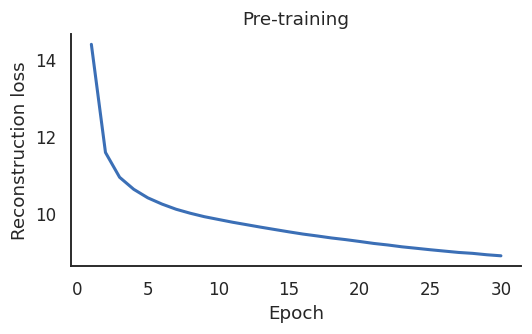

In [7]:
hist_pre = pretrain_vae(model, dl_rna, optimizer_pre, CFG["epochs_pretrain"], device)

plt.figure(figsize=(5, 3.2))
plt.plot(range(1, len(hist_pre) + 1), hist_pre, color="#3b6fb6", lw=2)
plt.xlabel("Epoch"); plt.ylabel("Reconstruction loss"); plt.title("Pre-training")
plt.tight_layout(); plt.show()

## K-Means trên mu của scRNA-seq để khởi tạo pi, mu_c, var_c

In [8]:
info = initialize_gmm_parameters(model, dl_rna, n_clusters, device, seed=CFG["seed"])
label_to_cluster = info["label_to_cluster"]

assert (label_to_cluster >= 0).all(), "Có nhãn chưa được ghép cụm: kiểm tra n_clusters"
print("Ánh xạ nhãn -> cụm GMM:")
for lbl, clu in enumerate(label_to_cluster.tolist()):
    print(f"  {class_names[lbl]:<25} -> cụm {clu}")
print("pi:", np.round(info["pi"].cpu().numpy(), 3))

Ánh xạ nhãn -> cụm GMM:
  ExE endoderm              -> cụm 1
  Intermediate mesoderm     -> cụm 0
  Haematoendothelial progenitors -> cụm 10
  Surface ectoderm          -> cụm 2
  Allantois                 -> cụm 3
  Endothelium               -> cụm 9
  Forebrain/Midbrain/Hindbrain -> cụm 4
  Spinal cord               -> cụm 7
  Cardiomyocytes            -> cụm 8
  NMP                       -> cụm 6
  Neural crest              -> cụm 5
pi: [0.087 0.155 0.098 0.068 0.128 0.132 0.084 0.104 0.036 0.061 0.047]


## huấn luyện chung. Tạo optimizer mới

In [9]:
optimizer_joint = torch.optim.Adam(model.parameters(), lr=CFG["lr_joint"])

def grl_lambda(progress, gamma=10.0):
    return 2.0 / (1.0 + math.exp(-gamma * progress)) - 1.0

E = CFG["epochs_joint"]
hist_joint = []
for ep in range(E):
    lam = grl_lambda(ep / max(E - 1, 1))
    h = train_joint_gmm_vae(
        model, dl_rna, dl_spa, optimizer_joint,
        epochs=1,
        lambda_1=CFG["lambda_1"], lambda_2=CFG["lambda_2"], lambda_grl=lam,
        device=device,
        label_to_cluster=label_to_cluster,
    )[0]
    h["lambda_grl"] = lam
    hist_joint.append(h)

hist_df = pd.DataFrame(hist_joint)

[Joint] Epoch 1/1 - total: 40.7057 | recon: 32.2173 | gmm: 40.1144 | domain: 0.4654 | z_aug/batch: 81.0
[Joint] Epoch 1/1 - total: 33.1302 | recon: 30.2800 | gmm: 12.6721 | domain: 0.3158 | z_aug/batch: 81.2
[Joint] Epoch 1/1 - total: 31.9748 | recon: 29.6404 | gmm: 9.7910 | domain: 0.3762 | z_aug/batch: 81.2
[Joint] Epoch 1/1 - total: 31.4773 | recon: 29.2521 | gmm: 8.9466 | domain: 0.4358 | z_aug/batch: 81.0
[Joint] Epoch 1/1 - total: 31.1323 | recon: 28.9958 | gmm: 8.5089 | domain: 0.4347 | z_aug/batch: 81.4
[Joint] Epoch 1/1 - total: 30.8387 | recon: 28.7931 | gmm: 8.1909 | domain: 0.4073 | z_aug/batch: 81.5
[Joint] Epoch 1/1 - total: 30.6586 | recon: 28.6783 | gmm: 7.9209 | domain: 0.3962 | z_aug/batch: 81.1
[Joint] Epoch 1/1 - total: 30.7191 | recon: 28.6213 | gmm: 7.8491 | domain: 0.5280 | z_aug/batch: 81.2
[Joint] Epoch 1/1 - total: 30.8053 | recon: 28.5887 | gmm: 7.7209 | domain: 0.6724 | z_aug/batch: 81.3
[Joint] Epoch 1/1 - total: 30.5013 | recon: 28.4399 | gmm: 7.5143 | dom

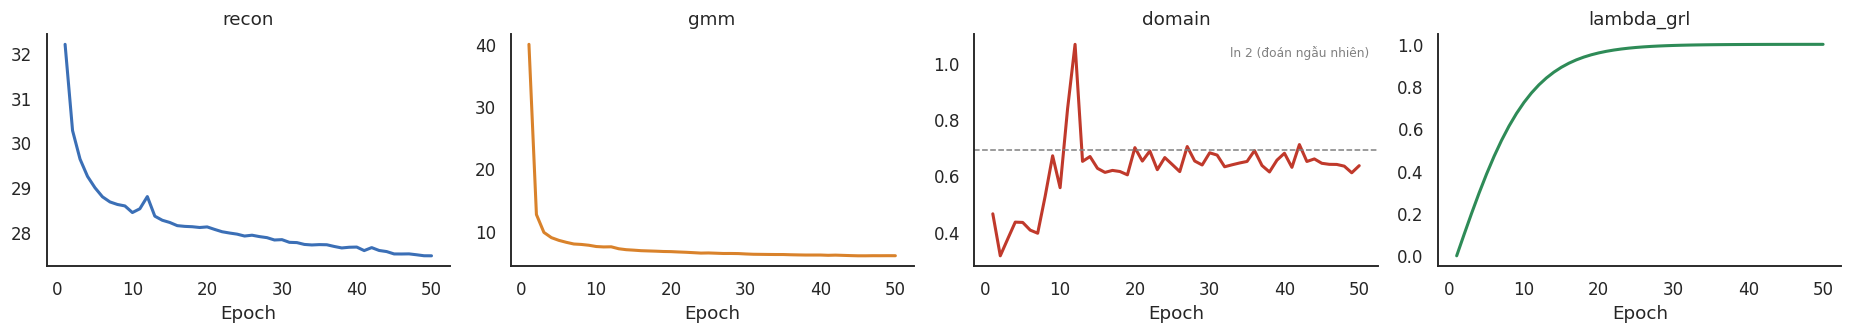

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.2))
for ax, (col, color) in zip(axes, [("recon", "#3b6fb6"), ("gmm", "#d9822b"),
                                    ("domain", "#c0392b"), ("lambda_grl", "#2e8b57")]):
    ax.plot(hist_df.index + 1, hist_df[col], color=color, lw=2)
    ax.set_title(col); ax.set_xlabel("Epoch")
axes[2].axhline(math.log(2), ls="--", c="gray", lw=1)
axes[2].text(0.98, 0.9, "ln 2 (đoán ngẫu nhiên)", transform=axes[2].transAxes,
             ha="right", fontsize=8, color="gray")
plt.tight_layout(); plt.show()

## Trích xuất không gian ẩn

In [11]:
@torch.no_grad()
def extract_latent(model, dataset, batch_size, device):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, drop_last=False)
    zs, ys, gs = [], [], []
    for x, y, _ in loader:
        mu, _ = model.encoder(x.to(device))
        zs.append(mu.cpu())
        gs.append(model.get_gamma(mu).cpu())
        ys.append(y)
    return torch.cat(zs).numpy(), torch.cat(ys).numpy(), torch.cat(gs).numpy()

model.eval()
Z_rna, y_rna, gamma_rna = extract_latent(model, ds_rna, CFG["batch_size"], device)
Z_spa, y_spa, gamma_spa = extract_latent(model, ds_spa, CFG["batch_size"], device)
print("Z_rna:", Z_rna.shape, "| Z_spa:", Z_spa.shape)

Z_rna: (32569, 32) | Z_spa: (52568, 32)


# Evaluate

In [12]:
rng = np.random.default_rng(CFG["seed"])
n_plot = min(CFG["max_cells_plot"], len(Z_rna), len(Z_spa))
idx_r = np.sort(rng.choice(len(Z_rna), n_plot, replace=False))
idx_s = np.sort(rng.choice(len(Z_spa), n_plot, replace=False))

Z_plot = np.vstack([Z_rna[idx_r], Z_spa[idx_s]])
domain = np.array(["scRNA-seq"] * n_plot + ["Spatial (ST)"] * n_plot)
is_rna = domain == "scRNA-seq"

ad = sc.AnnData(Z_plot.astype(np.float32))
sc.pp.neighbors(ad, n_neighbors=15, use_rep="X")
sc.tl.umap(ad, random_state=CFG["seed"])
emb_umap = ad.obsm["X_umap"]

emb_tsne = TSNE(n_components=2, perplexity=30, init="pca",
                random_state=CFG["seed"], n_jobs=-1).fit_transform(Z_plot)

embeddings = {"UMAP": emb_umap, "t-SNE": emb_tsne}

In [13]:
def style_axis(ax, title, name):
    ax.set_title(title, fontsize=12, weight="bold")
    ax.set_xlabel(f"{name} 1"); ax.set_ylabel(f"{name} 2")
    ax.set_xticks([]); ax.set_yticks([])

def scatter_cat(ax, emb, labels, palette, s=5, alpha=0.8):
    for lab, color in palette.items():
        m = labels == lab
        ax.scatter(emb[m, 0], emb[m, 1], s=s, c=[color], alpha=alpha,
                   linewidths=0, rasterized=True, label=lab)

domain_palette = {"scRNA-seq": "#3b6fb6", "Spatial (ST)": "#e07b39"}

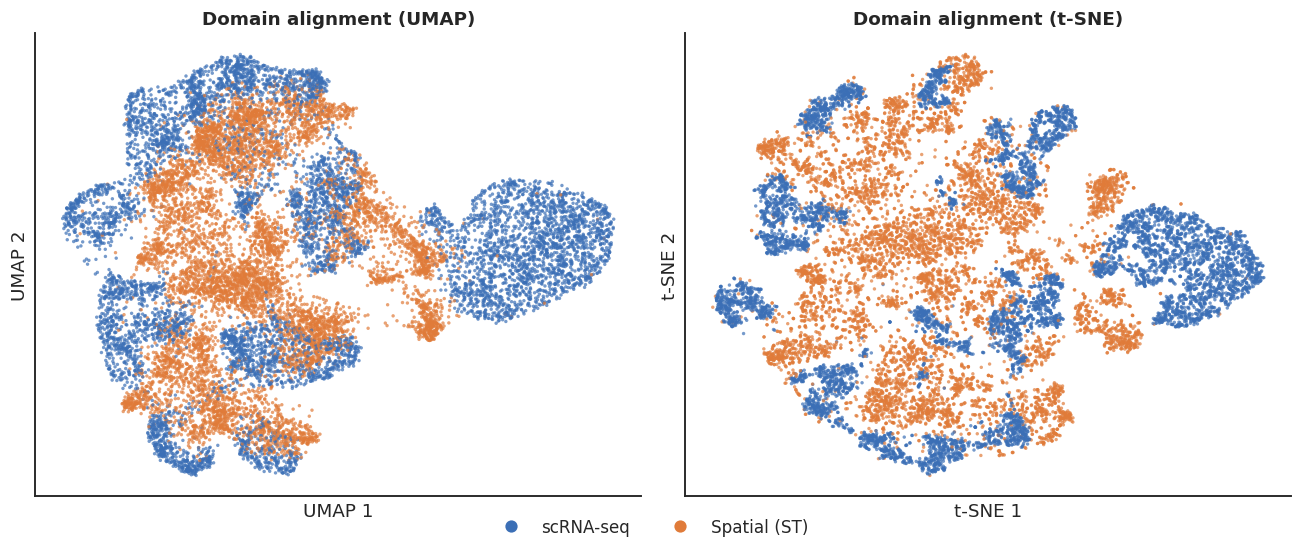

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
order = rng.permutation(len(domain))
for ax, (name, emb) in zip(axes, embeddings.items()):
    for dom, color in domain_palette.items():
        pass
    ax.scatter(emb[order, 0], emb[order, 1], s=5, linewidths=0, rasterized=True, alpha=0.7,
               c=[domain_palette[d] for d in domain[order]])
    style_axis(ax, f"Domain alignment ({name})", name)

handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=k, markersize=7)
           for k, c in domain_palette.items()]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(); plt.savefig("fig1_domain_alignment.png", bbox_inches="tight"); plt.show()

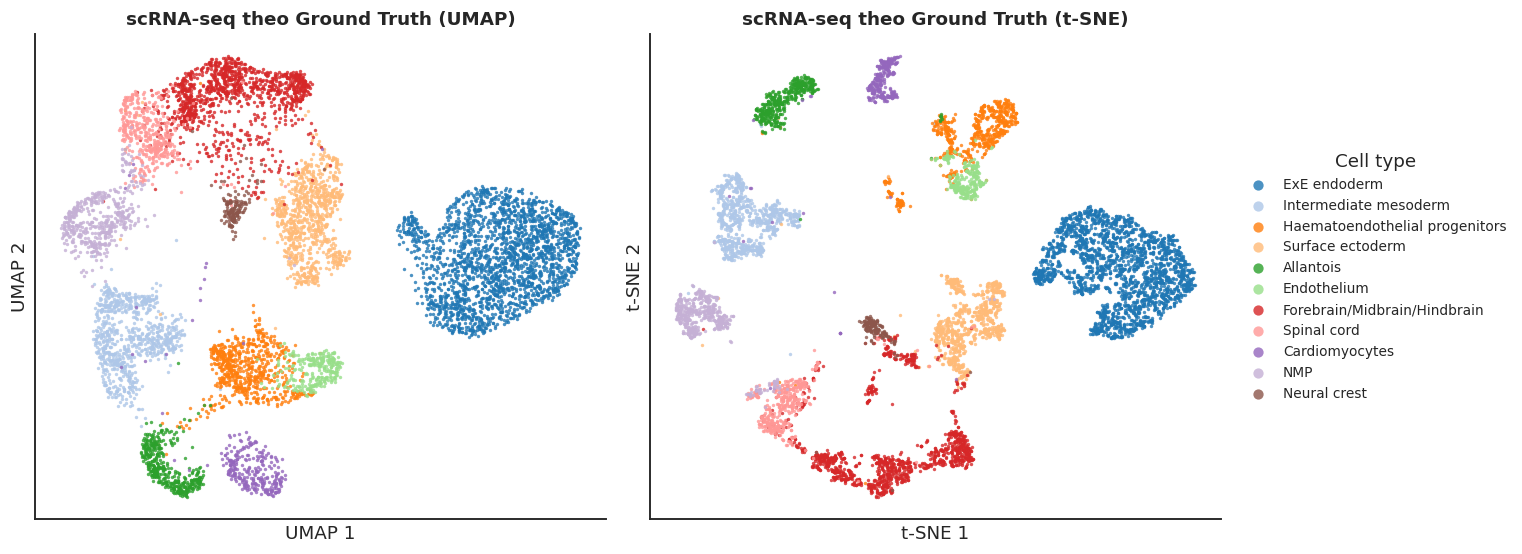

In [15]:
labels_rna_plot = np.array([class_names[i] for i in y_rna[idx_r]])

type_palette = dict(zip(class_names, sns.color_palette("husl", len(class_names))
                        if len(class_names) > 20 else sns.color_palette("tab20", len(class_names))))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, (name, emb) in zip(axes, embeddings.items()):
    scatter_cat(ax, emb[is_rna], labels_rna_plot, type_palette)
    style_axis(ax, f"scRNA-seq theo Ground Truth ({name})", name)
axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False,
               markerscale=3, fontsize=9, title="Cell type")
plt.tight_layout(); plt.savefig("fig2_source_celltype.png", bbox_inches="tight"); plt.show()

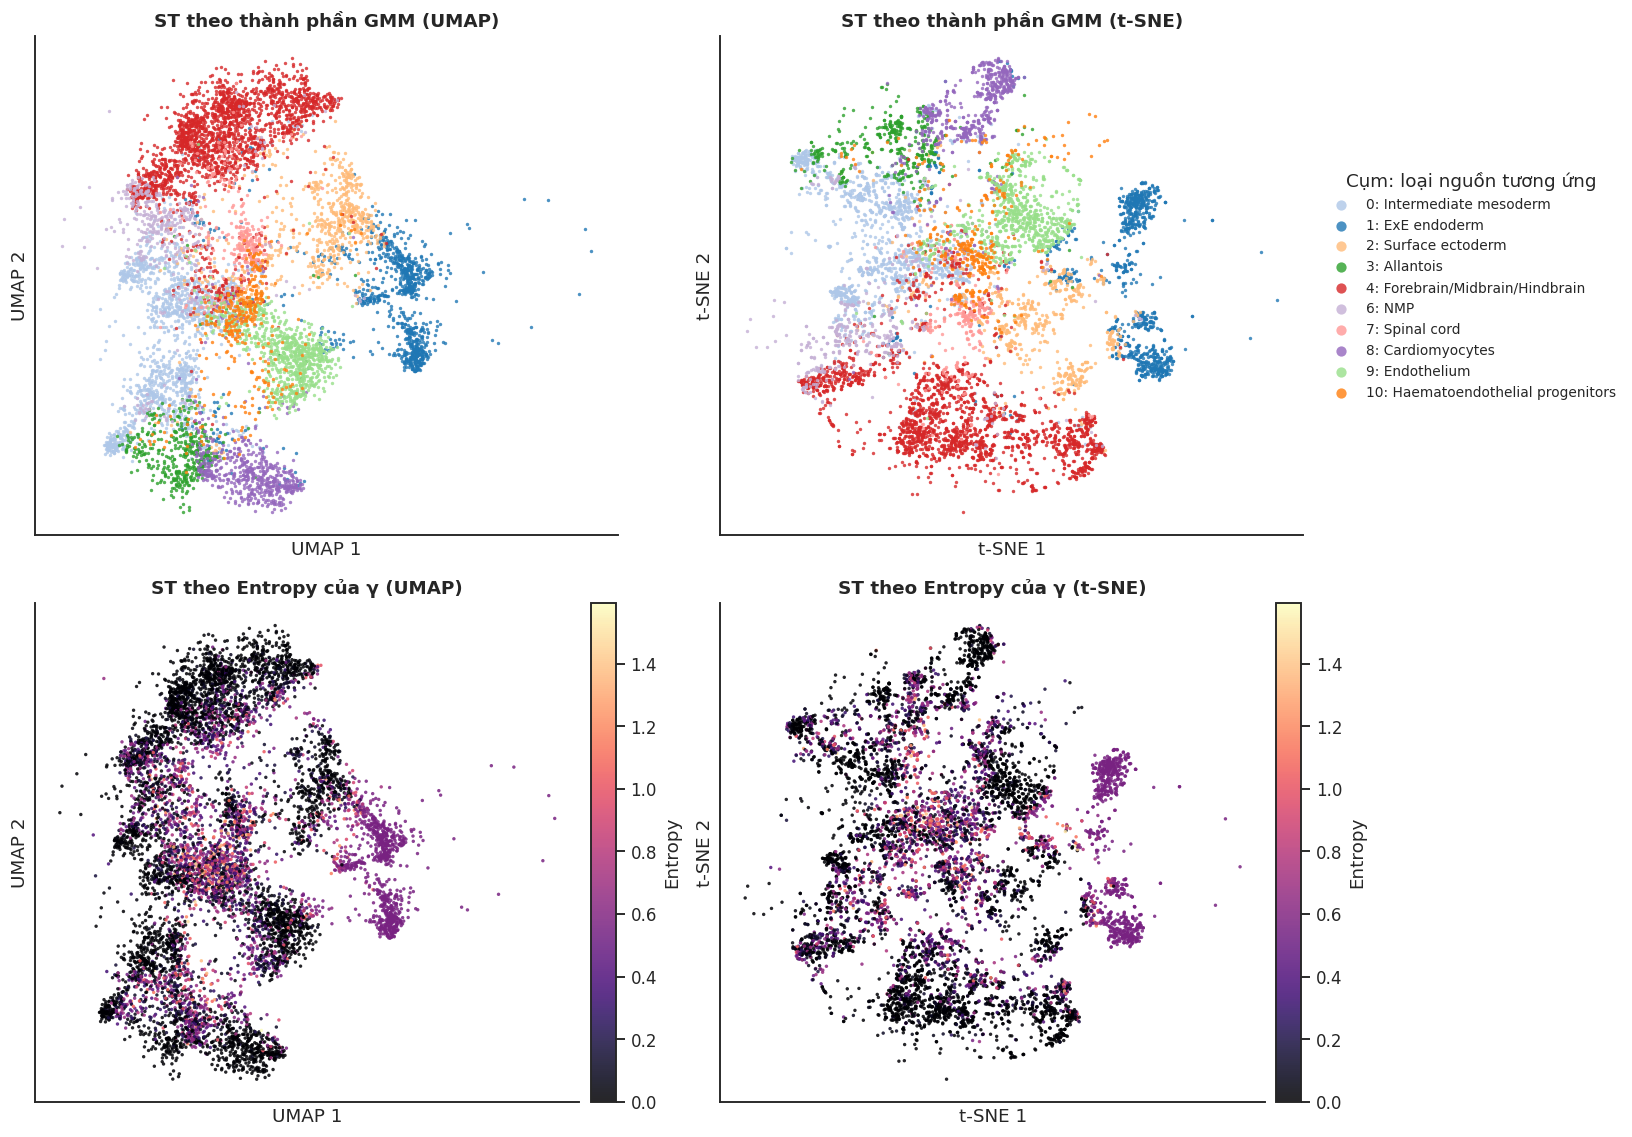

In [16]:
g = gamma_spa[idx_s]
comp = g.argmax(1)
entropy = -(g * np.log(g + 1e-10)).sum(1)
cluster_to_label = {int(c): class_names[l] for l, c in enumerate(label_to_cluster.tolist())}

# Tạo lưới 2x2: Hàng 1 (GMM), Hàng 2 (Entropy) | Cột 1 (UMAP), Cột 2 (t-SNE)
fig, axes = plt.subplots(2, 2, figsize=(15, 10.5))

# --- HÀNG 1: ST theo thành phần GMM ---
for idx, (name, emb_full) in enumerate(embeddings.items()):
    ax = axes[0, idx]
    emb = emb_full[~is_rna]

    for c in np.unique(comp):
        m = comp == c
        cell_type = cluster_to_label.get(c, '?')
        # LẤY MÀU TỪ TYPE_PALETTE CỦA Cell 1 ĐỂ ĐỒNG BỘ
        color = type_palette.get(cell_type, '#333333')

        ax.scatter(emb[m, 0], emb[m, 1], s=5, c=[color], linewidths=0, alpha=0.8,
                   rasterized=True, label=f"{c}: {cell_type}" if idx == 1 else "")

    style_axis(ax, f"ST theo thành phần GMM ({name})", name)

# Đặt legend cho Hàng 1 (nằm ở rìa ngoài cùng bên phải của đồ thị t-SNE)
axes[0, 1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False,
                  markerscale=3, fontsize=9, title="Cụm: loại nguồn tương ứng")

# --- HÀNG 2: ST theo Entropy ---
for idx, (name, emb_full) in enumerate(embeddings.items()):
    ax = axes[1, idx]
    emb = emb_full[~is_rna]

    sc_ = ax.scatter(emb[:, 0], emb[:, 1], s=5, c=entropy, cmap="magma",
                     linewidths=0, alpha=0.85, rasterized=True)
    style_axis(ax, f"ST theo Entropy của γ ({name})", name)
    cb = plt.colorbar(sc_, ax=ax, fraction=0.046, pad=0.02)
    cb.set_label("Entropy")

plt.tight_layout(); plt.savefig("fig3_target_structure.png", bbox_inches="tight"); plt.show()

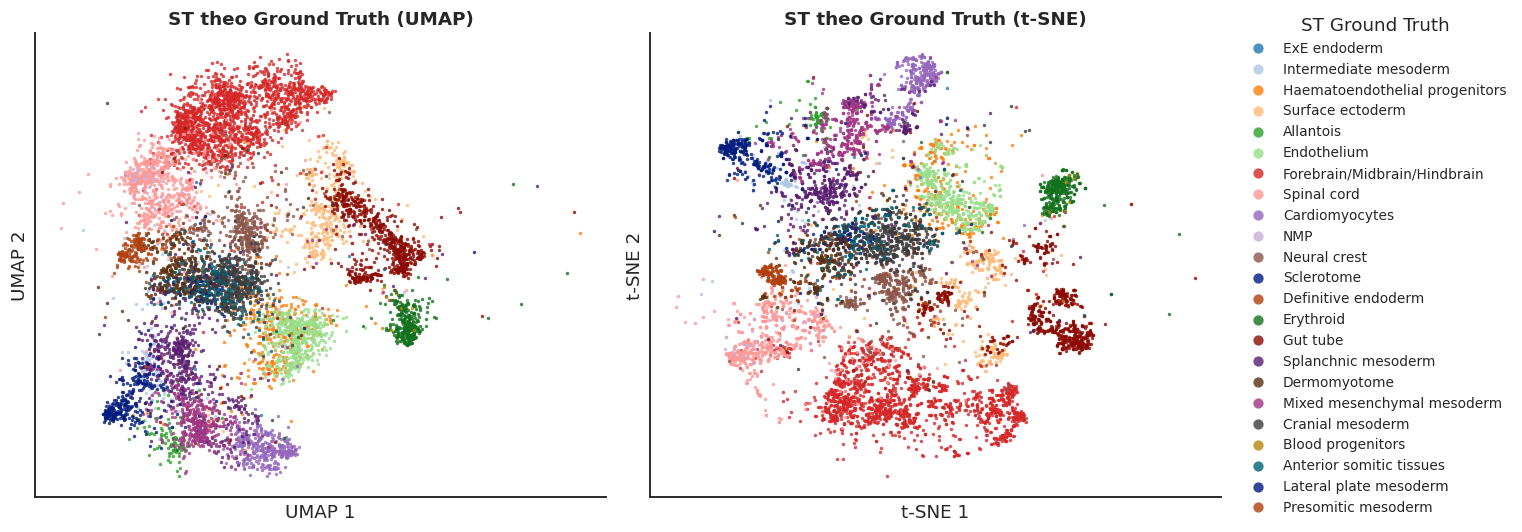

In [17]:
labels_spa_plot = adata_spa.obs[CFG["label_col"]].values[idx_s]
new_labels = set(labels_spa_plot) - set(type_palette.keys())
if new_labels:
    extra_colors = sns.color_palette("dark", len(new_labels))
    for label, color in zip(new_labels, extra_colors):
        type_palette[label] = color

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

for ax, (name, emb) in zip(axes, embeddings.items()):
    scatter_cat(ax, emb[~is_rna], labels_spa_plot, type_palette)
    style_axis(ax, f"ST theo Ground Truth ({name})", name)

axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False,
               markerscale=3, fontsize=9, title="ST Ground Truth")

plt.tight_layout()
plt.savefig("fig4_target_groundtruth.png", bbox_inches="tight")
plt.show()

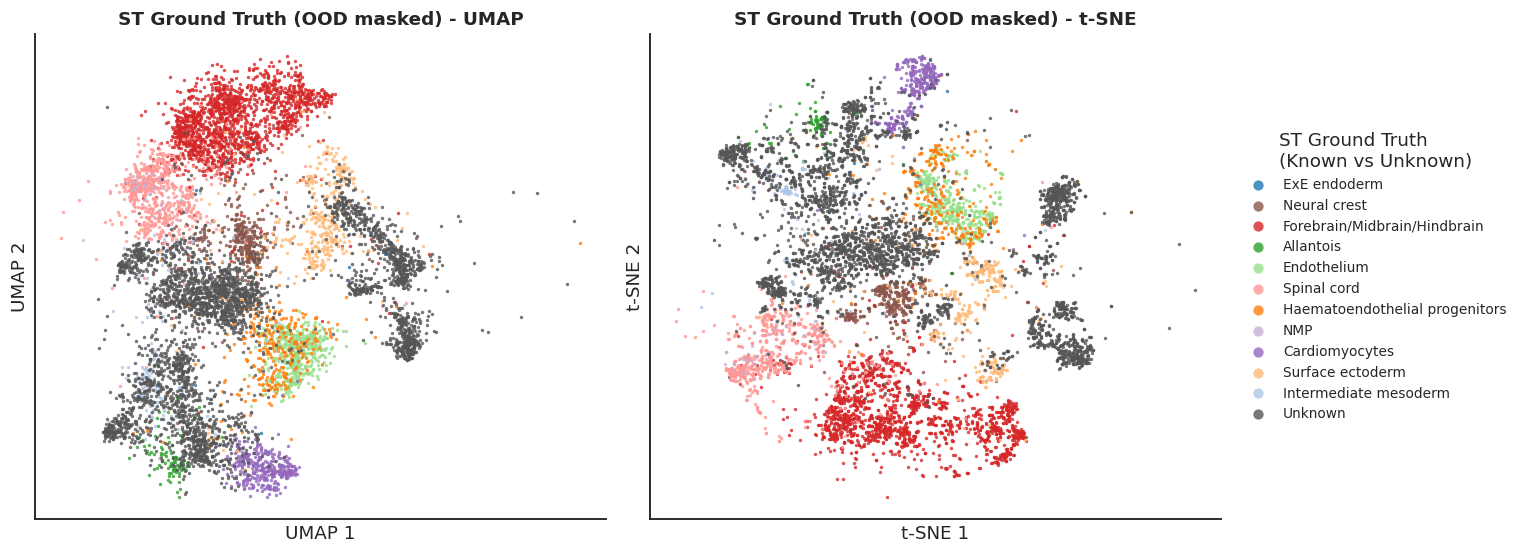

In [18]:
import numpy as np

labels_spa_original = adata_spa.obs[CFG["label_col"]].values[idx_s]

known_labels = set(class_names)

labels_spa_grouped = np.array([
    label if label in known_labels else "Unknown"
    for label in labels_spa_original
])

palette_unknown = {label: type_palette[label] for label in known_labels}
palette_unknown["Unknown"] = "#555555" # Màu xám đậm (Dark Gray) để dễ nhận diện

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

for ax, (name, emb) in zip(axes, embeddings.items()):
    emb_spa = emb[~is_rna]

    scatter_cat(ax, emb_spa, labels_spa_grouped, palette_unknown)
    style_axis(ax, f"ST Ground Truth (OOD masked) - {name}", name)

axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False,
               markerscale=3, fontsize=9, title="ST Ground Truth\n(Known vs Unknown)")

plt.tight_layout()
plt.savefig("fig5_target_groundtruth_unknown.png", bbox_inches="tight")
plt.show()

,ARI,NMI,Số cụm dùng
Phương pháp,,,
K-Means trên Z,0.8681,0.8682,11
GMM (argmax γ),0.8898,0.8936,10


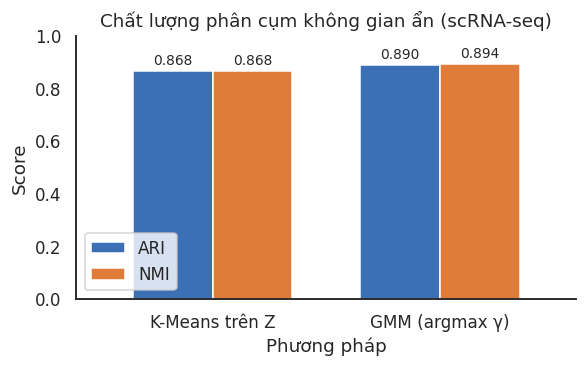

In [19]:
km_pred = KMeans(n_clusters=n_clusters, n_init=10, random_state=CFG["seed"]).fit_predict(Z_rna)
gmm_pred = gamma_rna.argmax(1)

rows = []
for name, pred in [("K-Means trên Z", km_pred), ("GMM (argmax γ)", gmm_pred)]:
    rows.append({"Phương pháp": name,
                 "ARI": adjusted_rand_score(y_rna, pred),
                 "NMI": normalized_mutual_info_score(y_rna, pred),
                 "Số cụm dùng": len(np.unique(pred))})

metrics_df = pd.DataFrame(rows).set_index("Phương pháp").round(4)
display(metrics_df)

ax = metrics_df[["ARI", "NMI"]].plot.bar(figsize=(5.5, 3.5), color=["#3b6fb6", "#e07b39"], rot=0, width=0.7)
ax.set_ylim(0, 1); ax.set_ylabel("Score"); ax.set_title("Chất lượng phân cụm không gian ẩn (scRNA-seq)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=9, padding=2)
plt.tight_layout(); plt.show()

In [20]:
nn_ = NearestNeighbors(n_neighbors=31).fit(Z_plot)
_, nbr_feat = nn_.kneighbors(Z_plot)
nbr_feat = nbr_feat[:, 1:]
other_frac = (is_rna[nbr_feat] != is_rna[:, None]).mean(1)

print(f"Tỉ lệ láng giềng khác miền (trung bình): {other_frac.mean():.3f}  (lý tưởng ≈ 0.5)")
print(f"  - scRNA-seq: {other_frac[is_rna].mean():.3f} | ST: {other_frac[~is_rna].mean():.3f}")

Tỉ lệ láng giềng khác miền (trung bình): 0.120  (lý tưởng ≈ 0.5)
  - scRNA-seq: 0.000 | ST: 0.241


In [21]:
torch.save({"model": model.state_dict(), "label_mapping": label_mapping,
            "config": CFG, "hidden_dims": hidden_dims}, "gmm_vae_stage12.pt")
np.savez("latent_stage12.npz", Z_rna=Z_rna, y_rna=y_rna, gamma_rna=gamma_rna,
         Z_spa=Z_spa, gamma_spa=gamma_spa)

# Huấn luyện gán nhãn

In [22]:
K = n_clusters
prior_uni = torch.full((K,), 1.0 / K, device=device)

cluster_to_lbl = torch.empty(K, dtype=torch.long)
cluster_to_lbl[label_to_cluster.cpu()] = torch.arange(K)
cluster_to_lbl = cluster_to_lbl.numpy()

def to_label_idx(pseudo_cluster):
    pc = np.asarray(pseudo_cluster)
    return np.where(pc >= 0, cluster_to_lbl[np.clip(pc, 0, None)], -1)

def open_set_report(pred, y_true, name=""):
    known, unk = y_true >= 0, y_true < 0
    accepted = pred >= 0
    kk = accepted & known
    known_acc = np.mean([(pred[y_true == c] == c).mean() for c in np.unique(y_true[known])])
    unk_rec = (pred[unk] == -1).mean() if unk.any() else np.nan
    return {
        "name": name,
        "accepted": accepted.mean(),
        "known_acc": known_acc,
        "unknown_recall": unk_rec,
        "H-score": 2 * known_acc * unk_rec / (known_acc + unk_rec + 1e-12),
        "pseudo_purity": (pred[kk] == y_true[kk]).mean() if kk.any() else np.nan,
        "unk_in_accepted": unk[accepted].mean() if accepted.any() else np.nan,
    }

@torch.no_grad()
def calibrate_tau_H(model, q):
    z = extract_mu(model, ds_rna, device)
    g = model.get_gamma(z, pi=prior_uni)
    H = -(g * torch.log(g + 1e-10)).sum(1) / math.log(K)
    return float(np.percentile(H.cpu().numpy(), q))

## Đồ thị láng giềng không gian của ST

In [26]:
if "spatial" in adata_spa.obsm:
    coords = np.asarray(adata_spa.obsm["spatial"])
else:
    coords = adata_spa.obs[["X", "Y"]].to_numpy(dtype=float)
assert coords.shape[0] == len(ds_spa), "coords phải cùng số hàng và thứ tự với ST"

nbr_spa = build_spatial_neighbors(coords, k=CFG["spatial_k"])

lab_spa = adata_spa.obs[CFG["label_col"]].astype(str).to_numpy(dtype=object)
same = (lab_spa[nbr_spa.numpy()] == lab_spa[:, None]).mean()
print(f"Tỉ lệ láng giềng không gian cùng nhãn thật: {same:.3f}")

Tỉ lệ láng giềng không gian cùng nhãn thật: 0.571


## Baseline Giai đoạn 2 (chưa tự huấn luyện)

In [27]:
nbr_dev = nbr_spa.to(device)
Z_spa_t = extract_mu(model, ds_spa, device)
prior_spatial0 = compute_prior(model, Z_spa_t, "spatial", nbr_dev, CFG["prior_alpha"])

rows_base = []
for q in (90, 95, 99):
    tau = calibrate_tau_H(model, q)
    for pname, prior in [("đều", prior_uni), ("không gian", prior_spatial0)]:
        r0 = dual_rejection(model, Z_spa_t, prior, tau_H=tau, chi2_conf=CFG["chi2_conf"])
        pred0 = to_label_idx(r0["pseudo_labels"].cpu().numpy())
        rows_base.append(open_set_report(pred0, y_spa, f"Stage 2 | prior {pname} | q={q} (tau_H={tau:.3f})"))
display(pd.DataFrame(rows_base).set_index("name").round(3))

,accepted,known_acc,unknown_recall,H-score,pseudo_purity,unk_in_accepted
name,,,,,,
Stage 2 | prior đều | q=90 (tau_H=0.289),0.777,0.488,0.296,0.369,0.681,0.397
Stage 2 | prior không gian | q=90 (tau_H=0.289),0.809,0.496,0.244,0.327,0.689,0.409
Stage 2 | prior đều | q=95 (tau_H=0.289),0.780,0.488,0.289,0.363,0.681,0.399
Stage 2 | prior không gian | q=95 (tau_H=0.289),0.812,0.496,0.239,0.323,0.689,0.410
Stage 2 | prior đều | q=99 (tau_H=0.289),0.805,0.488,0.234,0.316,0.680,0.417
Stage 2 | prior không gian | q=99 (tau_H=0.289),0.825,0.496,0.209,0.295,0.689,0.420


In [28]:
if CFG["freeze_pi_uniform"]:
    model.pi_logits.data.zero_()
    model.pi_logits.requires_grad_(False)

optimizer_st = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=CFG["lr_st"])

hist3, rows3 = [], []
for r in range(CFG["rounds"]):
    tau_H = calibrate_tau_H(model, CFG["tau_q"])
    h_r, res = train_self_training(
        model, dl_rna, dl_spa, optimizer_st,
        rounds=1, epochs_per_round=CFG["epochs_per_round"],
        lambda_1=CFG["lambda_1"], lambda_2=CFG["lambda_2"], lambda_3=CFG["lambda_3"],
        lambda_grl=1.0, device=device, label_to_cluster=label_to_cluster,
        nbr=nbr_spa, prior_mode="spatial", alpha=CFG["prior_alpha"],
        tau_H=tau_H, chi2_conf=CFG["chi2_conf"],
    )
    for h in h_r:
        h["round"] = r + 1
    hist3 += h_r
    pred_r = to_label_idx(res["pseudo_labels"].cpu().numpy())
    rows3.append(open_set_report(pred_r, y_spa, f"round {r + 1} (tau_H={tau_H:.3f})"))

metrics3 = pd.DataFrame(rows_base[2:4] + rows3).set_index("name").round(3)
display(metrics3)

[Round 1/1] accepted: 81.2% | unknown: 18.8% | chi2 thr: 46.2
  ep 1/5 - total: 37.280 | recon: 29.962 | gmm: 5.659 | domain: 0.627 | pseudo: 18.531
  ep 2/5 - total: 34.413 | recon: 30.152 | gmm: 5.720 | domain: 0.622 | pseudo: 8.315
  ep 3/5 - total: 34.122 | recon: 30.104 | gmm: 5.692 | domain: 0.613 | pseudo: 7.554
  ep 4/5 - total: 33.959 | recon: 30.081 | gmm: 5.674 | domain: 0.611 | pseudo: 7.105
  ep 5/5 - total: 33.830 | recon: 30.053 | gmm: 5.639 | domain: 0.608 | pseudo: 6.806
[Round 1/1] accepted: 85.3% | unknown: 14.7% | chi2 thr: 46.2
  ep 1/5 - total: 33.656 | recon: 30.050 | gmm: 5.633 | domain: 0.587 | pseudo: 6.310
  ep 2/5 - total: 33.550 | recon: 30.051 | gmm: 5.628 | domain: 0.580 | pseudo: 5.978
  ep 3/5 - total: 33.465 | recon: 30.033 | gmm: 5.603 | domain: 0.579 | pseudo: 5.775
  ep 4/5 - total: 33.401 | recon: 30.019 | gmm: 5.584 | domain: 0.578 | pseudo: 5.621
  ep 5/5 - total: 33.357 | recon: 30.024 | gmm: 5.565 | domain: 0.577 | pseudo: 5.478
[Round 1/1] acc

,accepted,known_acc,unknown_recall,H-score,pseudo_purity,unk_in_accepted
name,,,,,,
Stage 2 | prior đều | q=95 (tau_H=0.289),0.780,0.488,0.289,0.363,0.681,0.399
Stage 2 | prior không gian | q=95 (tau_H=0.289),0.812,0.496,0.239,0.323,0.689,0.410
round 1 (tau_H=0.289),0.846,0.557,0.283,0.375,0.701,0.371
round 2 (tau_H=0.289),0.892,0.560,0.197,0.291,0.698,0.394
round 3 (tau_H=0.289),0.921,0.557,0.137,0.220,0.695,0.410
round 4 (tau_H=0.289),0.935,0.557,0.112,0.187,0.690,0.416
round 5 (tau_H=0.289),0.939,0.557,0.104,0.176,0.689,0.418


## Tự huấn luyện (nhiều round)


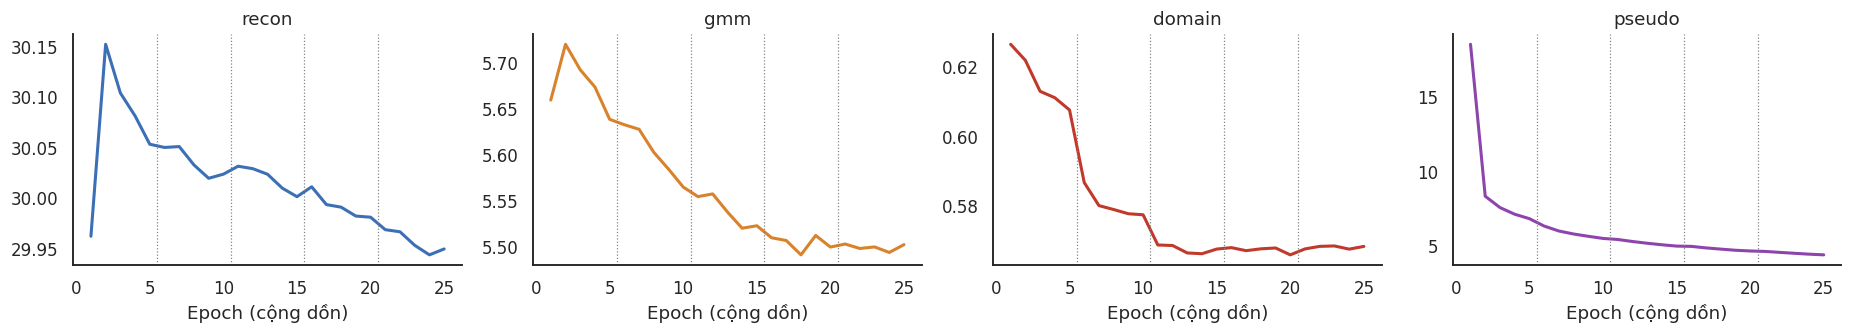

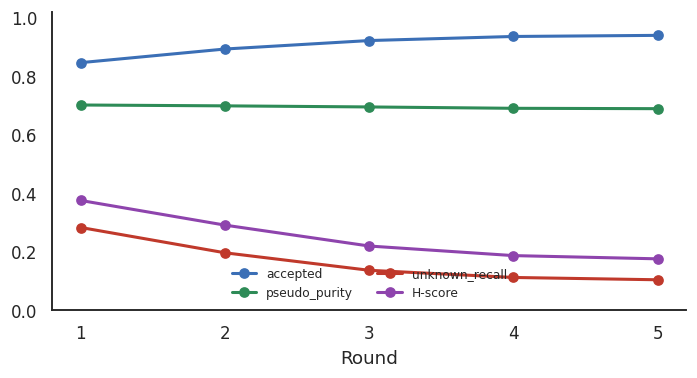

In [29]:
h3 = pd.DataFrame(hist3)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.2))
for ax, (col, color) in zip(axes, [("recon", "#3b6fb6"), ("gmm", "#d9822b"),
                                    ("domain", "#c0392b"), ("pseudo", "#8e44ad")]):
    ax.plot(np.arange(1, len(h3) + 1), h3[col], color=color, lw=2)
    for r in range(1, CFG["rounds"]):
        ax.axvline(r * CFG["epochs_per_round"] + 0.5, color="gray", ls=":", lw=0.8)
    ax.set_title(col); ax.set_xlabel("Epoch (cộng dồn)")
plt.tight_layout(); plt.show()

m3 = pd.DataFrame(rows3)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
x = np.arange(1, len(m3) + 1)
for col, c in [("accepted", "#3b6fb6"), ("pseudo_purity", "#2e8b57"),
               ("unknown_recall", "#c0392b"), ("H-score", "#8e44ad")]:
    ax.plot(x, m3[col], marker="o", label=col, color=c, lw=2)
ax.set_xticks(x); ax.set_xlabel("Round"); ax.set_ylim(0, 1.02)
ax.legend(frameon=False, fontsize=8, ncol=2, loc="lower center")
plt.tight_layout(); plt.show()

## Trích xuất lại không gian ẩn và trực quan hóa

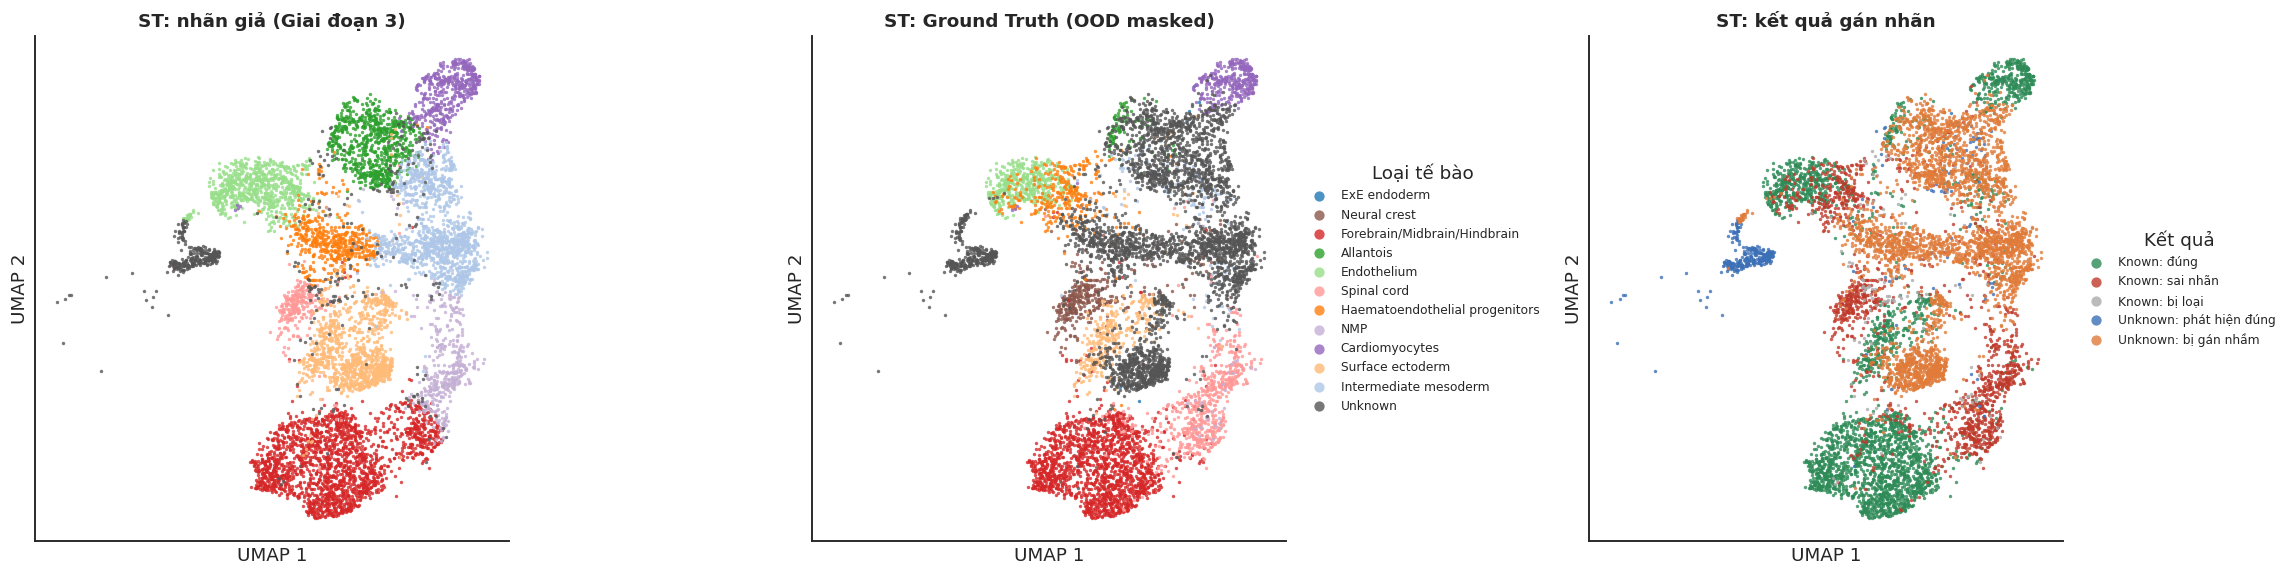

In [30]:
model.eval()
Z_rna3, y_rna3, gamma_rna3 = extract_latent(model, ds_rna, CFG["batch_size"], device)
Z_spa3, _, _ = extract_latent(model, ds_spa, CFG["batch_size"], device)

Z_plot3 = np.vstack([Z_rna3[idx_r], Z_spa3[idx_s]])
ad3 = sc.AnnData(Z_plot3.astype(np.float32))
sc.pp.neighbors(ad3, n_neighbors=15, use_rep="X")
sc.tl.umap(ad3, random_state=CFG["seed"])
emb3_spa = ad3.obsm["X_umap"][~is_rna]

pl_final = res["pseudo_labels"].cpu().numpy()
pred_idx = to_label_idx(pl_final)
pred_names_all = np.array([class_names[i] if i >= 0 else "Unknown" for i in pred_idx])

y_s, p_s = y_spa[idx_s], pred_idx[idx_s]
outcome = np.select(
    [(y_s >= 0) & (p_s == y_s), (y_s >= 0) & (p_s >= 0), (y_s >= 0) & (p_s < 0), (y_s < 0) & (p_s < 0)],
    ["Known: đúng", "Known: sai nhãn", "Known: bị loại", "Unknown: phát hiện đúng"],
    default="Unknown: bị gán nhầm",
)
outcome_palette = {"Known: đúng": "#2e8b57", "Known: sai nhãn": "#c0392b", "Known: bị loại": "#aaaaaa",
                   "Unknown: phát hiện đúng": "#3b6fb6", "Unknown: bị gán nhầm": "#e07b39"}

fig, axes = plt.subplots(1, 3, figsize=(21, 5.4))
scatter_cat(axes[0], emb3_spa, pred_names_all[idx_s], palette_unknown)
style_axis(axes[0], "ST: nhãn giả (Giai đoạn 3)", "UMAP")
scatter_cat(axes[1], emb3_spa, labels_spa_grouped, palette_unknown)
style_axis(axes[1], "ST: Ground Truth (OOD masked)", "UMAP")
axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, markerscale=3,
               fontsize=8, title="Loại tế bào")
scatter_cat(axes[2], emb3_spa, outcome, outcome_palette)
style_axis(axes[2], "ST: kết quả gán nhãn", "UMAP")
axes[2].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, markerscale=3,
               fontsize=8, title="Kết quả")
plt.tight_layout(); plt.savefig("fig6_stage3_pseudolabels.png", bbox_inches="tight"); plt.show()

## Chẩn đoán hai chốt chặn


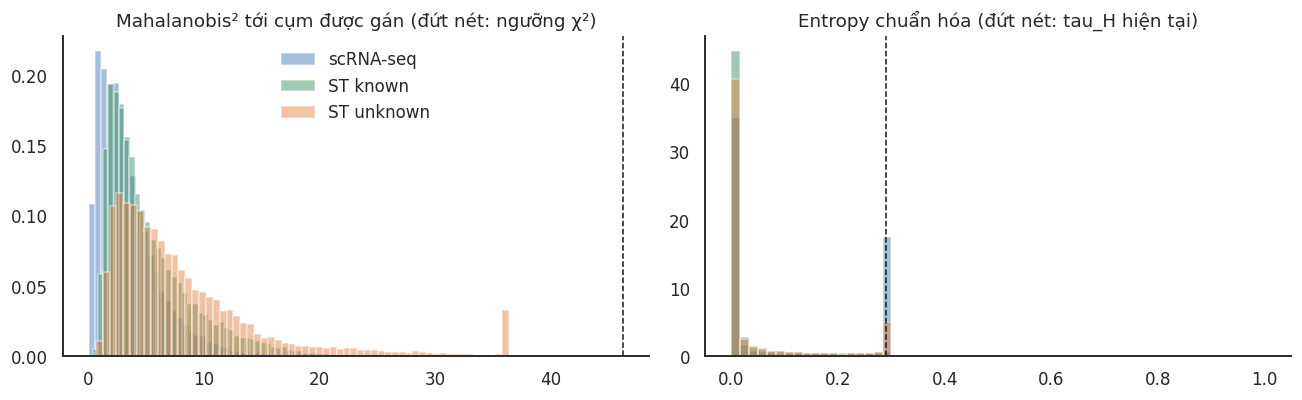

In [31]:
with torch.no_grad():
    mu_src = extract_mu(model, ds_rna, device)
    r_src = dual_rejection(model, mu_src, prior_uni, tau_H=1.0, chi2_conf=CFG["chi2_conf"])

d2_src, H_src = r_src["d2"].cpu().numpy(), r_src["entropy"].cpu().numpy()
d2_st, H_st = res["d2"].cpu().numpy(), res["entropy"].cpu().numpy()
known_st = y_spa >= 0
tau_now = calibrate_tau_H(model, CFG["tau_q"])

groups = [("scRNA-seq", d2_src, H_src, "#3b6fb6"),
          ("ST known", d2_st[known_st], H_st[known_st], "#2e8b57"),
          ("ST unknown", d2_st[~known_st], H_st[~known_st], "#e07b39")]
hi = np.percentile(np.r_[d2_src, d2_st], 99.5)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, d2, H, c in groups:
    if len(d2) == 0:
        continue
    axes[0].hist(np.clip(d2, 0, hi), bins=60, density=True, alpha=0.45, color=c, label=name)
    axes[1].hist(H, bins=60, range=(0, 1), density=True, alpha=0.45, color=c, label=name)
axes[0].axvline(res["d2_thr"], color="k", ls="--", lw=1)
axes[0].set_title("Mahalanobis² tới cụm được gán (đứt nét: ngưỡng χ²)"); axes[0].legend(frameon=False)
axes[1].axvline(tau_now, color="k", ls="--", lw=1)
axes[1].set_title("Entropy chuẩn hóa (đứt nét: tau_H hiện tại)")
plt.tight_layout(); plt.show()

## Giai đoạn 3 có làm hỏng cấu trúc cụm hoặc độ trộn miền không?


In [34]:
import copy

def src_scores(Z, gamma, y):
    km = KMeans(n_clusters=K, n_init=10, random_state=CFG["seed"]).fit_predict(Z)
    gm = gamma.argmax(1)
    return {"ARI_kmeans": adjusted_rand_score(y, km), "NMI_kmeans": normalized_mutual_info_score(y, km),
            "ARI_gmm": adjusted_rand_score(y, gm), "NMI_gmm": normalized_mutual_info_score(y, gm)}

def mixing(Z, is_rna, k=30):
    _, ix = NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z)
    return (is_rna[ix[:, 1:]] != is_rna[:, None]).mean()

def open_set_metrics(pred, y_true):
    known, unk = y_true >= 0, y_true < 0
    kacc = (pred[known] == y_true[known]).mean()
    uacc = (pred[unk] == -1).mean() if unk.any() else np.nan
    tacc = (pred == y_true).mean()
    h = 2 * kacc * uacc / (kacc + uacc + 1e-12)
    return {"KACC": kacc, "UACC": uacc, "TACC": tacc, "H-score": h}

cmp_df = pd.DataFrame({
    "Stage 2": {**src_scores(Z_rna, gamma_rna, y_rna), "mixing": mixing(Z_plot, is_rna)},
    "Stage 3": {**src_scores(Z_rna3, gamma_rna3, y_rna3), "mixing": mixing(Z_plot3, is_rna)},
}).round(4)
display(cmp_df)

rows_os = {}
ckpt_path = "gmm_vae_stage12.pt"
if os.path.exists(ckpt_path):
    model2 = copy.deepcopy(model)
    model2.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=False)["model"])
    model2.eval()
    Z2 = extract_mu(model2, ds_spa, device)
    tau2 = calibrate_tau_H(model2, CFG["tau_q"])
    priors2 = {"Stage 2 | prior đều": prior_uni,
               "Stage 2 | prior không gian": compute_prior(model2, Z2, "spatial", nbr_dev, CFG["prior_alpha"])}
    for name, prior in priors2.items():
        r2 = dual_rejection(model2, Z2, prior, tau_H=tau2, chi2_conf=CFG["chi2_conf"])
        rows_os[name] = open_set_metrics(to_label_idx(r2["pseudo_labels"].cpu().numpy()), y_spa)
else:
    print(f"Không thấy {ckpt_path}: chỉ tính Stage 3.")

rows_os["Stage 3 (round cuối)"] = open_set_metrics(pred_idx, y_spa)
display(pd.DataFrame(rows_os).T.round(4))

,Stage 2,Stage 3
ARI_kmeans,0.8681,0.8650
NMI_kmeans,0.8682,0.8535
ARI_gmm,0.8898,0.8177
NMI_gmm,0.8936,0.8692
mixing,0.1204,0.1920


,KACC,UACC,TACC,H-score
Stage 2 | prior đều,0.5685,0.2891,0.4462,0.3833
Stage 2 | prior không gian,0.5868,0.2393,0.4347,0.3400
Stage 3 (round cuối),0.6699,0.1045,0.4223,0.1808


In [33]:
torch.save({"model": model.state_dict(), "label_mapping": label_mapping, "config": CFG,
            "hidden_dims": hidden_dims, "label_to_cluster": label_to_cluster}, "gmm_vae_stage3.pt")
np.savez("pseudo_labels_stage3.npz", pseudo=pl_final, pred_names=pred_names_all,
         entropy=res["entropy"].cpu().numpy(), d2=res["d2"].cpu().numpy(), Z_spa=Z_spa3)
adata_spa.obs["pseudo_label"] = pred_names_all